# Regression Modelling

This notebook develops and evaluates regression models for predicting the number of goals scored by a team in a FIFA World Cup 2026 match.


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from scipy import stats

pd.set_option("display.max_columns", None)

In [2]:
# Load prepared dataset
df = pd.read_excel(
    "Regression_2_2_Final_Model_Data.xlsx"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (208, 12)


In [3]:
# Define target
target = "Goals_For"

# Define 8 predictors
features = [
    "Team_PreTournament_FIFA_Rank",
    "Opponent_PreTournament_FIFA_Rank",
    "Team_PreMatch_Goals_PG",
    "Opponent_PreMatch_GoalsAgainst_PG",
    "Team_PreMatch_GoalsAgainst_PG",
    "Opponent_PreMatch_Points_PG",
    "Team_PreMatch_Possession_Avg",
    "Team_PreMatch_Points_PG"
]

X = df[features].copy()
y = df[target].copy()

# MatchID is used for grouping
groups = df["MatchID"].copy()

print("Predictors:", len(features))
print("Observations:", len(X))
print("Matches:", groups.nunique())

Predictors: 8
Observations: 208
Matches: 104


In [4]:
# Split data by match
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

In [5]:
# Check train-test split
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Training matches:",
    groups_train.nunique()
)

print(
    "Testing matches:",
    groups_test.nunique()
)

match_overlap = (
    set(groups_train)
    & set(groups_test)
)

print(
    "Matches in both sets:",
    len(match_overlap)
)

Training rows: 166
Testing rows: 42
Training matches: 83
Testing matches: 21
Matches in both sets: 0


The dataset was split by `MatchID` so that the two observations from the same match remain together.

The test set is kept separate from model development and is only used after the final model has been selected.

In [6]:
# Five-fold grouped cross-validation
group_cv = GroupKFold(
    n_splits=5
)

# Evaluation metrics
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

In [7]:
# Baseline Linear Regression pipeline
baseline_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regressor",
        LinearRegression()
    )
])

baseline_model.fit(
    X_train,
    y_train
)

print("Baseline Linear Regression fitted.")

Baseline Linear Regression fitted.


In [8]:
# Training predictions
baseline_train_pred = baseline_model.predict(
    X_train
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        baseline_train_pred
    )
)

train_mae = mean_absolute_error(
    y_train,
    baseline_train_pred
)

train_r2 = r2_score(
    y_train,
    baseline_train_pred
)

baseline_train_metrics = pd.DataFrame({
    "Metric": [
        "RMSE",
        "MAE",
        "R2"
    ],
    "Training_Value": [
        train_rmse,
        train_mae,
        train_r2
    ]
})

baseline_train_metrics.round(3)

,Metric,Training_Value
0,RMSE,1.203
1,MAE,0.910
2,R2,0.229


In [9]:
# Cross-validate baseline model
baseline_cv = cross_validate(
    baseline_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring=scoring
)

baseline_cv_summary = pd.DataFrame({
    "Metric": [
        "RMSE",
        "MAE",
        "R2"
    ],
    "Mean": [
        -baseline_cv["test_RMSE"].mean(),
        -baseline_cv["test_MAE"].mean(),
        baseline_cv["test_R2"].mean()
    ],
    "Std": [
        baseline_cv["test_RMSE"].std(),
        baseline_cv["test_MAE"].std(),
        baseline_cv["test_R2"].std()
    ]
})

baseline_cv_summary.round(3)

,Metric,Mean,Std
0,RMSE,1.284,0.216
1,MAE,0.981,0.164
2,R2,0.092,0.156


In [10]:
# Create out-of-fold predictions
baseline_oof_pred = cross_val_predict(
    baseline_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv
)

# Calculate out-of-fold residuals
baseline_oof_residuals = (
    y_train.to_numpy()
    - baseline_oof_pred
)

print("Out-of-fold predictions created.")
print("Number of predictions:", len(baseline_oof_pred))

Out-of-fold predictions created.
Number of predictions: 166


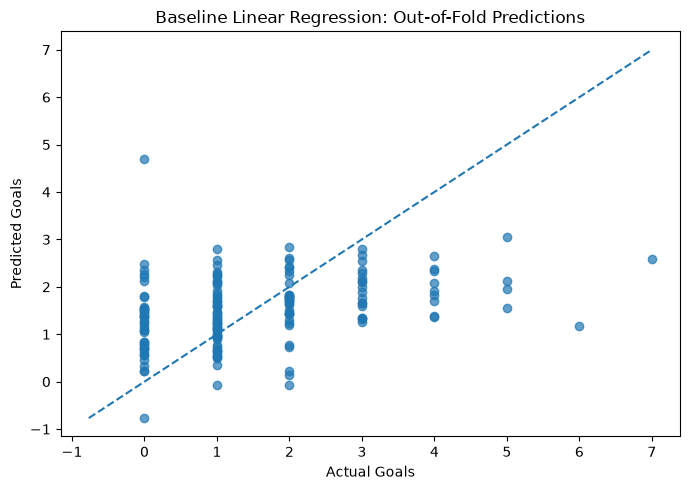

In [11]:
# Out-of-fold actual vs predicted
plt.figure(figsize=(7, 5))

plt.scatter(
    y_train,
    baseline_oof_pred,
    alpha=0.7
)

min_value = min(
    y_train.min(),
    baseline_oof_pred.min()
)

max_value = max(
    y_train.max(),
    baseline_oof_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Goals")
plt.ylabel("Predicted Goals")
plt.title(
    "Baseline Linear Regression: Out-of-Fold Predictions"
)

plt.tight_layout()
plt.show()

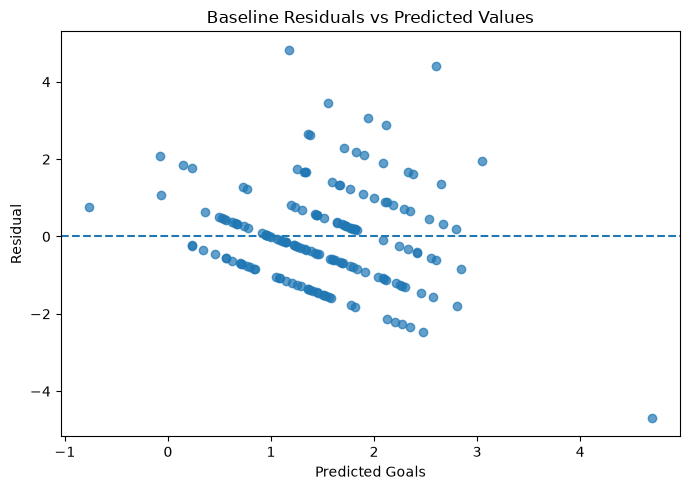

In [12]:
# Residuals vs predicted values
plt.figure(figsize=(7, 5))

plt.scatter(
    baseline_oof_pred,
    baseline_oof_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Goals")
plt.ylabel("Residual")
plt.title(
    "Baseline Residuals vs Predicted Values"
)

plt.tight_layout()
plt.show()

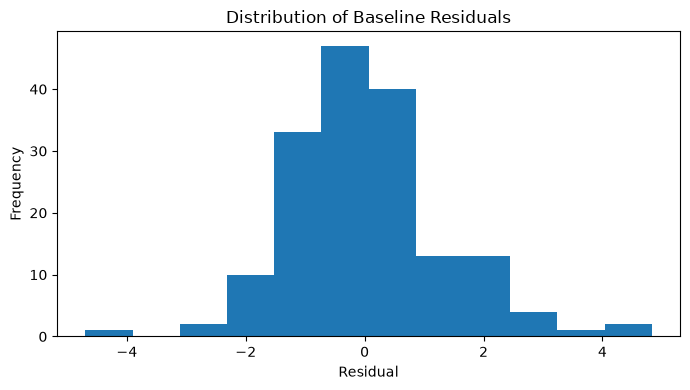

In [13]:
# Residual distribution
plt.figure(figsize=(7, 4))

plt.hist(
    baseline_oof_residuals,
    bins=12
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title(
    "Distribution of Baseline Residuals"
)

plt.tight_layout()
plt.show()

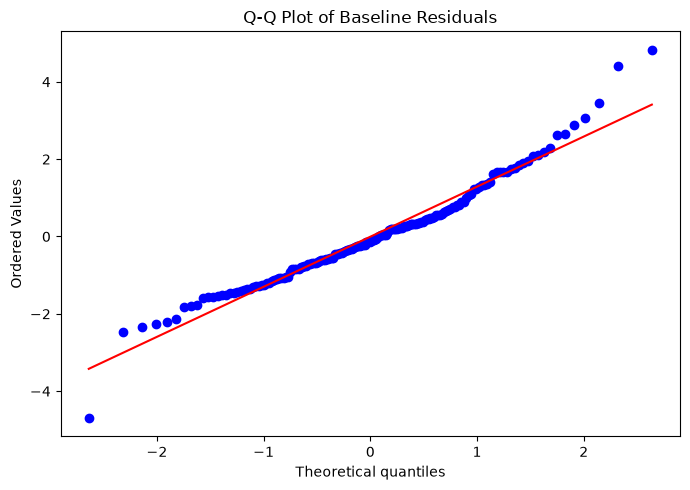

In [14]:
# Q-Q plot of residuals
plt.figure(figsize=(7, 5))

stats.probplot(
    baseline_oof_residuals,
    dist="norm",
    plot=plt
)

plt.title(
    "Q-Q Plot of Baseline Residuals"
)

plt.tight_layout()
plt.show()

In [15]:
# Check negative predictions
negative_oof_predictions = (
    baseline_oof_pred < 0
).sum()

print(
    "Negative out-of-fold predictions:",
    negative_oof_predictions
)

Negative out-of-fold predictions: 3


In [16]:
# Impute training data for VIF
vif_imputer = SimpleImputer(
    strategy="median"
)

X_vif_array = vif_imputer.fit_transform(
    X_train
)

X_vif = pd.DataFrame(
    X_vif_array,
    columns=features
)

vif_results = []

for feature in features:

    y_vif = X_vif[feature]

    X_other = X_vif.drop(
        columns=feature
    )

    vif_model = LinearRegression()

    vif_model.fit(
        X_other,
        y_vif
    )

    r2_value = vif_model.score(
        X_other,
        y_vif
    )

    if np.isclose(
        1 - r2_value,
        0
    ):
        vif = np.inf
    else:
        vif = 1 / (
            1 - r2_value
        )

    vif_results.append({
        "Variable": feature,
        "VIF": vif
    })

vif_table = pd.DataFrame(
    vif_results
).sort_values(
    "VIF",
    ascending=False
)

vif_table.round(3)

,Variable,VIF
7,Team_PreMatch_Points_PG,5.018
2,Team_PreMatch_Goals_PG,3.174
4,Team_PreMatch_GoalsAgainst_PG,2.356
5,Opponent_PreMatch_Points_PG,2.123
0,Team_PreTournament_FIFA_Rank,1.919
6,Team_PreMatch_Possession_Avg,1.805
3,Opponent_PreMatch_GoalsAgainst_PG,1.770
1,Opponent_PreTournament_FIFA_Rank,1.441


The VIF values showed low to moderate multicollinearity. `Team_PreMatch_Points_PG` had the highest VIF of 5.02, while all other predictors had lower values. No variables were removed, and regularised regression models were used to help manage correlated predictors.

In [17]:
# Baseline standardized coefficients
baseline_coefficients = pd.DataFrame({
    "Variable": features,
    "Coefficient":
        baseline_model
        .named_steps["regressor"]
        .coef_
})

baseline_coefficients[
    "Absolute_Coefficient"
] = (
    baseline_coefficients[
        "Coefficient"
    ].abs()
)

baseline_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).round(3)

,Variable,Coefficient,Absolute_Coefficient
0,Team_PreTournament_FIFA_Rank,-0.364,0.364
1,Opponent_PreTournament_FIFA_Rank,0.359,0.359
3,Opponent_PreMatch_GoalsAgainst_PG,0.160,0.160
6,Team_PreMatch_Possession_Avg,0.148,0.148
7,Team_PreMatch_Points_PG,-0.129,0.129
4,Team_PreMatch_GoalsAgainst_PG,-0.086,0.086
2,Team_PreMatch_Goals_PG,0.077,0.077
5,Opponent_PreMatch_Points_PG,0.014,0.014


# Baseline Diagnostics

The residuals were generally centred around zero, although some large residuals were present. The Q-Q plot showed deviations at the tails, and the model tended to underpredict unusually high goal totals. Overall, the baseline model captured some linear relationships but struggled with extreme match outcomes.

In [18]:
# Ridge pipeline
ridge_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regressor",
        Ridge()
    )
])

ridge_params = {
    "regressor__alpha":
        np.logspace(
            -4,
            3,
            15
        )
}

ridge_search = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    scoring=scoring,
    refit="RMSE",
    cv=group_cv
)

ridge_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print(
    "Best Ridge alpha:",
    ridge_search.best_params_
)

print(
    "Best Ridge CV RMSE:",
    round(
        -ridge_search.best_score_,
        3
    )
)

Best Ridge alpha: {'regressor__alpha': np.float64(100.0)}
Best Ridge CV RMSE: 1.239


In [19]:
# Lasso pipeline
lasso_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regressor",
        Lasso(max_iter=50000)
    )
])

# Lasso tuning values
lasso_params = {
    "regressor__alpha": np.logspace(
        -4,
        1,
        12
    )
}

# Tune Lasso using grouped cross-validation
lasso_search = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    scoring=scoring,
    refit="RMSE",
    cv=group_cv
)

lasso_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print(
    "Best Lasso alpha:",
    lasso_search.best_params_
)

print(
    "Best Lasso CV RMSE:",
    round(
        -lasso_search.best_score_,
        3
    )
)

Best Lasso alpha: {'regressor__alpha': np.float64(0.05336699231206307)}
Best Lasso CV RMSE: 1.238


In [20]:
# Elastic Net pipeline
elastic_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regressor",
        ElasticNet(
            max_iter=50000
        )
    )
])

elastic_params = {
    "regressor__alpha":
        np.logspace(
            -4,
            1,
            12
        ),

    "regressor__l1_ratio": [
        0.10,
        0.25,
        0.50,
        0.75,
        0.90
    ]
}

elastic_search = GridSearchCV(
    elastic_pipeline,
    elastic_params,
    scoring=scoring,
    refit="RMSE",
    cv=group_cv
)

elastic_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print(
    "Best Elastic Net parameters:",
    elastic_search.best_params_
)

print(
    "Best Elastic Net CV RMSE:",
    round(
        -elastic_search.best_score_,
        3
    )
)

Best Elastic Net parameters: {'regressor__alpha': np.float64(0.1519911082952933), 'regressor__l1_ratio': 0.5}
Best Elastic Net CV RMSE: 1.235


In [21]:
# Get CV metrics from tuned models
def tuned_cv_metrics(search):

    idx = search.best_index_

    return {
        "RMSE":
            -search.cv_results_[
                "mean_test_RMSE"
            ][idx],

        "MAE":
            -search.cv_results_[
                "mean_test_MAE"
            ][idx],

        "R2":
            search.cv_results_[
                "mean_test_R2"
            ][idx]
    }


ridge_metrics = tuned_cv_metrics(
    ridge_search
)

lasso_metrics = tuned_cv_metrics(
    lasso_search
)

elastic_metrics = tuned_cv_metrics(
    elastic_search
)

baseline_rmse = (
    -baseline_cv[
        "test_RMSE"
    ].mean()
)

baseline_mae = (
    -baseline_cv[
        "test_MAE"
    ].mean()
)

baseline_r2 = (
    baseline_cv[
        "test_R2"
    ].mean()
)

In [22]:
# Compare models
cv_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge",
        "Lasso",
        "Elastic Net"
    ],

    "CV_RMSE": [
        baseline_rmse,
        ridge_metrics["RMSE"],
        lasso_metrics["RMSE"],
        elastic_metrics["RMSE"]
    ],

    "CV_MAE": [
        baseline_mae,
        ridge_metrics["MAE"],
        lasso_metrics["MAE"],
        elastic_metrics["MAE"]
    ],

    "CV_R2": [
        baseline_r2,
        ridge_metrics["R2"],
        lasso_metrics["R2"],
        elastic_metrics["R2"]
    ]
})

cv_comparison = (
    cv_comparison
    .sort_values(
        "CV_RMSE"
    )
    .reset_index(
        drop=True
    )
)

cv_comparison.round(3)

,Model,CV_RMSE,CV_MAE,CV_R2
0,Elastic Net,1.235,0.957,0.170
1,Lasso,1.238,0.956,0.164
2,Ridge,1.239,0.955,0.164
3,Linear Regression,1.284,0.981,0.092


# Model Comparison

Linear Regression, Ridge, Lasso and Elastic Net were compared using grouped cross-validation. Elastic Net achieved the lowest cross-validation RMSE of approximately 1.24 and was therefore selected as the final model. Ridge and Lasso produced similar results, while the baseline Linear Regression performed slightly worse.

In [23]:
# Select model with lowest CV RMSE
best_model_name = (
    cv_comparison
    .iloc[0]["Model"]
)

model_lookup = {
    "Linear Regression":
        baseline_model,

    "Ridge":
        ridge_search.best_estimator_,

    "Lasso":
        lasso_search.best_estimator_,

    "Elastic Net":
        elastic_search.best_estimator_
}

final_model = model_lookup[
    best_model_name
]

print(
    "Selected model:",
    best_model_name
)

Selected model: Elastic Net


In [24]:
# Final test predictions
final_predictions = final_model.predict(
    X_test
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_predictions
    )
)

final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

final_metrics = pd.DataFrame({
    "Metric": [
        "RMSE",
        "MAE",
        "R2"
    ],

    "Value": [
        final_rmse,
        final_mae,
        final_r2
    ]
})

print(
    "Final model:",
    best_model_name
)

final_metrics.round(3)

Final model: Elastic Net


,Metric,Value
0,RMSE,1.249
1,MAE,0.967
2,R2,0.272


# Final Model Performance

On the held-out test set, Elastic Net achieved an RMSE of approximately 1.25 goals, an MAE of 0.97 goals and an R² of 0.27. The similar cross-validation and test RMSE values suggest reasonable generalisation, although substantial variation in goals scored remains unexplained.

In [25]:
# Check negative test predictions
negative_test_predictions = (
    final_predictions < 0
).sum()

print(
    "Negative test predictions:",
    negative_test_predictions
)

Negative test predictions: 0


In [26]:
# Final model coefficients
final_regressor = (
    final_model
    .named_steps["regressor"]
)

final_coefficients = pd.DataFrame({
    "Variable": features,
    "Coefficient":
        final_regressor.coef_
})

final_coefficients[
    "Absolute_Coefficient"
] = (
    final_coefficients[
        "Coefficient"
    ].abs()
)

final_coefficients = (
    final_coefficients
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
)

final_coefficients.round(3)

,Variable,Coefficient,Absolute_Coefficient
0,Team_PreTournament_FIFA_Rank,-0.295,0.295
1,Opponent_PreTournament_FIFA_Rank,0.291,0.291
6,Team_PreMatch_Possession_Avg,0.107,0.107
3,Opponent_PreMatch_GoalsAgainst_PG,0.095,0.095
2,Team_PreMatch_Goals_PG,0.000,0.000
4,Team_PreMatch_GoalsAgainst_PG,-0.000,0.000
5,Opponent_PreMatch_Points_PG,-0.000,0.000
7,Team_PreMatch_Points_PG,0.000,0.000


In [27]:
# Create final prediction table
prediction_results = (
    df.iloc[test_idx][
        [
            "MatchID",
            "Team",
            "Opponent",
            "Goals_For"
        ]
    ]
    .copy()
)

prediction_results[
    "Predicted_Goals"
] = final_predictions

prediction_results[
    "Residual"
] = (
    prediction_results[
        "Goals_For"
    ]
    - prediction_results[
        "Predicted_Goals"
    ]
)

prediction_results.head(10)

,MatchID,Team,Opponent,Goals_For,Predicted_Goals,Residual
0,1,Mexico,South Africa,2,2.069420,-0.069420
1,1,South Africa,Mexico,0,0.911083,-0.911083
8,5,Qatar,Switzerland,1,1.024300,-0.024300
9,5,Switzerland,Qatar,1,1.956007,-0.956007
20,11,Côte d'Ivoire,Ecuador,1,1.366107,-0.366107
21,11,Ecuador,Côte d'Ivoire,0,1.617920,-1.617920
24,13,Belgium,Egypt,1,1.745589,-0.745589
25,13,Egypt,Belgium,1,1.241964,-0.241964
36,19,Argentina,Algeria,3,1.834604,1.165396
37,19,Algeria,Argentina,0,1.154710,-1.154710


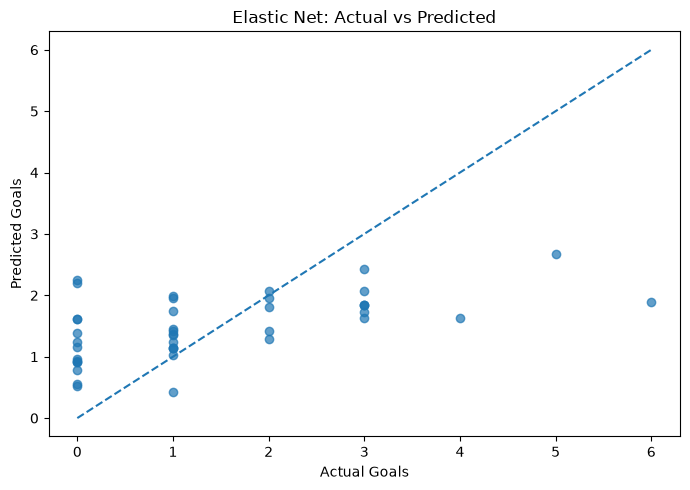

In [28]:
# Final actual vs predicted
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

min_value = min(
    y_test.min(),
    final_predictions.min()
)

max_value = max(
    y_test.max(),
    final_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Goals")
plt.ylabel("Predicted Goals")

plt.title(
    f"{best_model_name}: Actual vs Predicted"
)

plt.tight_layout()
plt.show()

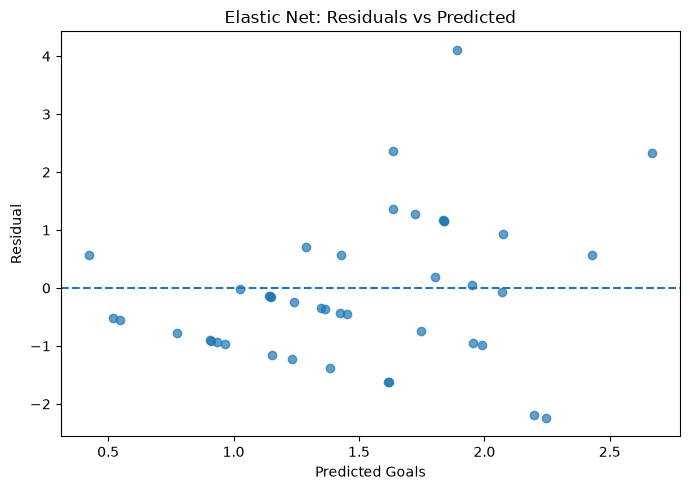

In [29]:
# Final residuals
final_residuals = (
    y_test.to_numpy()
    - final_predictions
)

plt.figure(figsize=(7, 5))

plt.scatter(
    final_predictions,
    final_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Goals")
plt.ylabel("Residual")

plt.title(
    f"{best_model_name}: Residuals vs Predicted"
)

plt.tight_layout()
plt.show()

In [30]:
# Save model comparison
cv_comparison.to_excel(
    "Regression_2_2_Model_Comparison.xlsx",
    index=False
)

# Save predictions
prediction_results.to_excel(
    "Regression_2_2_Final_Predictions.xlsx",
    index=False
)

# Save coefficients
final_coefficients.to_excel(
    "Regression_2_2_Final_Coefficients.xlsx",
    index=False
)

print(
    "Model results saved successfully."
)

Model results saved successfully.


In [31]:
# Final modelling validation
assert df.shape == (208, 12)
assert len(features) == 8
assert len(match_overlap) == 0
assert groups_train.nunique() + groups_test.nunique() == 104
assert len(final_predictions) == len(y_test)
assert np.isfinite(final_predictions).all()

assert best_model_name in [
    "Linear Regression",
    "Ridge",
    "Lasso",
    "Elastic Net"
]

print(
    "Regression modelling validation completed successfully."
)

Regression modelling validation completed successfully.


# Modelling Conclusion

Elastic Net provided the best overall performance among the four regression models evaluated. The selected pre-match variables provided useful information for predicting goals scored, although unusual high-scoring matches remained difficult to predict.

Overall, the model demonstrated moderate predictive ability while also showing the limitations of linear regression-based methods for football goal prediction.